# Cell2Sentence: muscle cell context for exercise mimetics

Implements the [project README's stretch goal](https://github.com/BioDATA-ASCENT/exercise-mimetics#4-stretch-goal-cell-type-context): apply exercise and drug expression shifts to real GTEx skeletal-muscle nuclei, then compare paired C2S embedding shifts within annotated cell types against an expression-weighted correlation baseline.

## Run on your M3 (36 GB)

1. Select `exmim-gpu` and restart the kernel after dependency changes.
2. Set paths and annotation columns in Cell 2. Start with three nuclei per type and 300 genes; set `CELL_TYPES` to exact labels from your reference to limit the run.
3. Run Cells 3-5 to load the model. Cell 5 downloads the pinned 5.23 GB checkpoint only when its cached snapshot is incomplete. The existing Hugging Face cache is reused, including previously downloaded files. A complete snapshot loads without Hub requests; set `OFFLINE=True` in Cell 5 to prohibit downloads explicitly. Do not delete the cache if you want to avoid downloading again.
4. Run Cells 6-8 after supplying inputs. To refresh presentation plots from saved comparisons without rerunning inference, run the final plotting cell. Results are written under `results/cell_context_c2s`.

## Inputs

- `data/gtex_sn_skeletalmuscle.h5ad`: real muscle nuclei with cell labels in `obs[CELL_TYPE_COLUMN]` and human gene symbols in `var[GENE_SYMBOL_COLUMN]`. Set the latter to `None` only if `var_names` are already symbols. Set `EXPRESSION_LAYER` to the layer containing linear-scale counts or normalized expression; `None` selects `X`. Do not use log1p, standardized expression, or Ensembl IDs. Duplicate symbols are summed; nuclei need at least 200 expressed genes. `X` is read in backed mode and only selected rows are densified; selecting a layer may require more RAM.
- `signatures/exercise/*.csv` or `*.tsv`: one exercise signature per file, preserving tissue/exercise/timepoint in its filename.
- `signatures/myotube/*.csv` or `*.tsv`: one drug signature per file, preserving drug/dose/time in its filename. Prefer muscle-matched myotube effects; LINCS signatures can be compared but are not equivalent evidence.
- Signature columns: `gene`, `score`, `direction`. Use unique human symbols, finite signed or magnitude scores, and `up`/`down`. No example data or model-generated gene lists substitute for real inputs.

## Method and caveats

`SIGNATURE_SCORE_MODE='rank_proxy'` treats shared ranked statistics as a bounded heuristic shift: `SHIFT_LOG2FC * tanh(signed_score / 95th-percentile absolute score)`. A t-statistic is not a log2 fold change. Use `'log2fc'` only when `score` genuinely contains measured log2 fold changes. Applied shifts multiply linear expression by `2 ** shift` and preserve the cell's total expression. Zero-expression genes remain zero. Repeat with different shift strengths to assess sensitivity.

Cell sentences contain the highest-expressed genes in rank order. Embeddings mean-pool the final transformer layer over gene tokens, excluding special tokens; this is an explicit exploratory extraction choice, not a validated C2S perturbation benchmark. No text generation or all-layer hidden-state retention is needed. Float16 MPS inference processes one sentence at a time.

For each sampled nucleus, compare `(drug embedding - baseline embedding)` against `(exercise embedding - baseline embedding)` using cosine similarity. The baseline is expression-weighted Pearson correlation of the applied shifts on jointly represented, expressed signature genes (at least three). Report gene coverage and valid counts alongside mean scores per cell type. Unchanged ranks produce unresolved model shifts, not evidence of no biology. Positive/negative scores indicate alignment/opposition only; these are not causal mimic/blunter calls, and agreement with a baseline is not proof the model beats it.

## Outputs

Per-nucleus and per-cell-type comparisons, signature overlap, sampled-nucleus identifiers and expression, applied gene shifts, pinned run settings/package versions, and comparison heatmaps. GEO-derived drug signatures are in `signatures/myotube`; see its README and `results/geo_myotube_signatures/manifest.csv` for provenance and filtering. Full-checkpoint inference still needs validation after the first complete download.

In [12]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REFERENCE_PATH = PROJECT_ROOT / "data" / "gtex_sn_skeletalmuscle.h5ad"
EXERCISE_DIR = PROJECT_ROOT / "signatures" / "exercise"
DRUG_DIR = PROJECT_ROOT / "signatures" / "myotube"
OUTPUT_DIR = PROJECT_ROOT / "results" / "cell_context_c2s"

CELL_TYPE_COLUMN = "Granular cell type"
GENE_SYMBOL_COLUMN = "Approved symbol"
EXPRESSION_LAYER = None
CELL_TYPES = None
CELLS_PER_TYPE = 3
TOP_GENES = 300
MIN_GENES = 200
SEED = 42

SIGNATURE_SCORE_MODE = "rank_proxy"
SHIFT_LOG2FC = 0.5

print(f"Reference: {REFERENCE_PATH}")
print(f"Exercise signatures: {EXERCISE_DIR}")
print(f"Drug signatures: {DRUG_DIR}")
print(f"Results: {OUTPUT_DIR}")

Reference: /Users/schwepa9/Desktop/Bioascent-hackathon/data/gtex_sn_skeletalmuscle.h5ad
Exercise signatures: /Users/schwepa9/Desktop/Bioascent-hackathon/signatures/exercise
Drug signatures: /Users/schwepa9/Desktop/Bioascent-hackathon/signatures/myotube
Results: /Users/schwepa9/Desktop/Bioascent-hackathon/results/cell_context_c2s


In [13]:
import sys
import platform
from importlib.metadata import version

print("Python:", sys.version)
print("Interpreter:", sys.executable)
print("Architecture:", platform.machine())
print("PyTorch:", version("torch"))

Python: 3.11.18 (main, Oct 26 2026, 11:32:31) [Clang 21.1.8 ]
Interpreter: /Users/schwepa9/miniconda3/envs/exmim-gpu/bin/python
Architecture: arm64
PyTorch: 2.15.0


In [14]:
import truststore

truststore.inject_into_ssl()

import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

if torch.backends.mps.is_available():
    device = torch.device("mps")
    model_dtype = torch.float16
elif torch.cuda.is_available():
    device = torch.device("cuda")
    model_dtype = torch.float16
else:
    device = torch.device("cpu")
    model_dtype = torch.float32

print(f"Device = {device}, model dtype = {model_dtype}")
if device.type == "cpu":
    print("Apple GPU unavailable. Check that the kernel uses ARM64 PyTorch with MPS support.")

Device = mps, model dtype = torch.float16


In [10]:
import json
from pathlib import Path
from huggingface_hub import snapshot_download
from huggingface_hub.constants import HF_HUB_CACHE

MODEL_ID = "vandijklab/C2S-Scale-Gemma-2-2B"
MODEL_REVISION = "5ddf28b8f1c81b7ab7a9be192924da82b6c5d512"
MODEL_CACHE = Path(HF_HUB_CACHE)
OFFLINE = False


def snapshot_is_complete(snapshot_path):
    snapshot_path = Path(snapshot_path)
    if not (snapshot_path / "config.json").is_file():
        return False
    if not any((snapshot_path / name).is_file() for name in ("tokenizer.json", "tokenizer.model")):
        return False
    index_path = snapshot_path / "model.safetensors.index.json"
    if index_path.is_file():
        weight_files = set(json.loads(index_path.read_text())["weight_map"].values())
        return bool(weight_files) and all((snapshot_path / name).is_file() for name in weight_files)
    return (snapshot_path / "model.safetensors").is_file()


def ensure_model_snapshot(offline=False):
    options = dict(repo_id=MODEL_ID, revision=MODEL_REVISION, cache_dir=str(MODEL_CACHE))
    try:
        snapshot_path = snapshot_download(**options, local_files_only=True)
    except FileNotFoundError:
        snapshot_path = None
    if snapshot_path is not None and snapshot_is_complete(snapshot_path):
        return Path(snapshot_path)
    if offline:
        raise FileNotFoundError("The pinned model snapshot is incomplete. Run once with OFFLINE=False to download it.")
    snapshot_path = snapshot_download(
        **options, allow_patterns=["*.json", "*.model", "*.safetensors"]
    )
    if not snapshot_is_complete(snapshot_path):
        raise RuntimeError("Model download is incomplete; rerun this cell to retry.")
    return Path(snapshot_path)


def load_cell_tokenizer(snapshot_path):
    cell_tokenizer = AutoTokenizer.from_pretrained(snapshot_path, use_fast=False, local_files_only=True)
    expected_vocab = json.loads((Path(snapshot_path) / "config.json").read_text())["vocab_size"]
    first = cell_tokenizer("MALAT1 ACTB", add_special_tokens=False)["input_ids"]
    second = cell_tokenizer("ACTB MALAT1", add_special_tokens=False)["input_ids"]
    if len(cell_tokenizer) < expected_vocab or first == second or cell_tokenizer.unk_token_id in first:
        raise RuntimeError("Invalid gene tokenizer. Use the compatible Transformers 4.x environment and restart the kernel.")
    return cell_tokenizer


model_path = ensure_model_snapshot(offline=OFFLINE)
print(f"Pinned local model: {model_path}")

if "model" in globals():
    del model
    gc.collect()
    if device.type == "mps":
        torch.mps.empty_cache()

tokenizer = load_cell_tokenizer(model_path)
model = AutoModelForCausalLM.from_pretrained(
    model_path,
    local_files_only=True,
    dtype=model_dtype,
    low_cpu_mem_usage=True,
    attn_implementation="eager",
).to(device).eval()
print(f"Loaded {MODEL_ID} on {device} using {next(model.parameters()).dtype}")

Pinned local model: /Users/schwepa9/.cache/huggingface/hub/models--vandijklab--C2S-Scale-Gemma-2-2B/snapshots/5ddf28b8f1c81b7ab7a9be192924da82b6c5d512


Loading checkpoint shards: 100%|██████████| 2/2 [00:05<00:00,  2.64s/it]


Loaded vandijklab/C2S-Scale-Gemma-2-2B on mps using torch.float16


In [15]:
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse


def read_signature(path, score_mode=SIGNATURE_SCORE_MODE):
    path = Path(path)
    table = pd.read_csv(path, sep="\t" if path.suffix == ".tsv" else ",")
    required = {"gene", "score", "direction"}
    if not required.issubset(table.columns):
        raise ValueError(f"{path.name}: required columns are gene, score, direction.")
    if table.empty or table["gene"].isna().any():
        raise ValueError(f"{path.name}: signature is empty or contains missing genes.")
    genes = table["gene"].astype(str).str.strip()
    if genes.eq("").any() or genes.duplicated().any():
        raise ValueError(f"{path.name}: gene symbols must be nonempty and unique.")
    scores = pd.to_numeric(table["score"], errors="raise").to_numpy(dtype=float)
    signs = table["direction"].astype(str).str.lower().str.strip().map(
        {"up": 1, "down": -1, "1": 1, "-1": -1, "+1": 1}
    )
    if signs.isna().any() or not np.isfinite(scores).all():
        raise ValueError(f"{path.name}: use finite scores and up/down directions.")
    signed_scores = np.abs(scores) * signs.to_numpy()
    if score_mode == "log2fc":
        shifts = signed_scores
    elif score_mode == "rank_proxy":
        scale = np.quantile(np.abs(scores), 0.95)
        shifts = SHIFT_LOG2FC * np.tanh(signed_scores / scale) if scale > 0 else signed_scores
    else:
        raise ValueError("SIGNATURE_SCORE_MODE must be rank_proxy or log2fc.")
    if not np.isfinite(shifts).all() or np.max(np.abs(shifts)) > 20:
        raise ValueError(f"{path.name}: implausibly large expression shifts; check score units.")
    return pd.Series(shifts, index=genes, name=path.stem)


def read_signature_directory(directory):
    paths = sorted(list(Path(directory).glob("*.csv")) + list(Path(directory).glob("*.tsv")))
    if len({path.stem for path in paths}) != len(paths):
        raise ValueError(f"Duplicate signature names in {directory}.")
    return {path.stem: read_signature(path) for path in paths}


def sample_reference(path):
    reference = sc.read_h5ad(path, backed="r")
    try:
        if CELL_TYPE_COLUMN not in reference.obs:
            raise ValueError(f"Set CELL_TYPE_COLUMN. Available columns: {list(reference.obs.columns)}")
        if GENE_SYMBOL_COLUMN is None:
            symbols = pd.Series(reference.var_names.astype(str))
        elif GENE_SYMBOL_COLUMN in reference.var:
            symbols = reference.var[GENE_SYMBOL_COLUMN].reset_index(drop=True).astype("string")
        else:
            raise ValueError(f"Set GENE_SYMBOL_COLUMN, or None for symbol-based var_names. Available: {list(reference.var.columns)}")
        valid = symbols.notna().to_numpy()
        symbol_values = symbols.fillna("").astype(str).str.strip().to_numpy()
        valid &= (symbol_values != "") & (symbol_values != "nan")
        if any(symbol.startswith("ENSG") for symbol in symbol_values[valid]):
            raise ValueError("Map Ensembl IDs to human gene symbols before constructing cell sentences.")
        genes, inverse = np.unique(symbol_values[valid], return_inverse=True)
        expression = reference.X if EXPRESSION_LAYER is None else reference.layers[EXPRESSION_LAYER]
        rng = np.random.default_rng(SEED)
        metadata, rows = [], []
        observations = reference.obs.copy()
        observations["_row"] = np.arange(reference.n_obs)
        for label, group in observations.dropna(subset=[CELL_TYPE_COLUMN]).groupby(CELL_TYPE_COLUMN, observed=True, sort=True):
            if CELL_TYPES is not None and label not in CELL_TYPES:
                continue
            selected = 0
            for row_index in rng.permutation(group["_row"].to_numpy()):
                row = expression[int(row_index), :]
                values = row.toarray().ravel() if sparse.issparse(row) else np.asarray(row).ravel()
                if not np.isfinite(values).all() or (values < 0).any():
                    raise ValueError("Reference expression must be finite, nonnegative, and linear-scale (not log1p or scaled).")
                collapsed = np.bincount(inverse, weights=values[valid], minlength=len(genes)).astype(np.float32)
                if np.count_nonzero(collapsed) < MIN_GENES:
                    continue
                rows.append(collapsed)
                metadata.append({"cell_id": str(reference.obs_names[row_index]), "cell_type": str(label), "reference_row": int(row_index)})
                selected += 1
                if selected >= CELLS_PER_TYPE:
                    break
            if selected < CELLS_PER_TYPE:
                print(f"{label}: using {selected} nuclei with at least {MIN_GENES} expressed genes.")
        if not rows:
            raise ValueError("No eligible nuclei. Check cell labels, gene symbols, and expression matrix.")
        return genes, np.stack(rows), pd.DataFrame(metadata)
    finally:
        reference.file.close()


exercise_signatures = read_signature_directory(EXERCISE_DIR)
drug_signatures = read_signature_directory(DRUG_DIR)
if REFERENCE_PATH.is_file() and exercise_signatures and drug_signatures:
    genes, reference_expression, cell_metadata = sample_reference(REFERENCE_PATH)
    print(cell_metadata.groupby("cell_type").size())
    print(f"Loaded {len(exercise_signatures)} exercise and {len(drug_signatures)} drug signatures.")
else:
    reference_expression = None
    print("Analysis inputs are not ready. Supply the GTEx muscle h5ad and exercise/drug CSV or TSV signatures at the configured paths.")

cell_type
Adipocyte                             3
Endothelial cell (lymphatic)          3
Endothelial cell (vascular) I         3
Endothelial cell (vascular) II        3
Endothelial cell (vascular) III       3
Fibroblast                            3
Immune (DC)                           3
Immune (DC/macrophage)                3
Immune (NK cell)                      3
Immune (T cell)                       3
Immune (macrophage)                   3
Immune (mast cell)                    3
Immune (neutrophil)                   3
Myocyte (NMJ-rich)                    3
Myocyte (fast-twitch)                 3
Myocyte (fast-twitch, cytoplasmic)    3
Myocyte (sk. muscle)                  3
Myocyte (slow-twitch, cytoplasmic)    3
Pericyte/SMC I                        3
Pericyte/SMC II                       3
Satellite cell                        3
Schwann cell                          3
dtype: int64
Loaded 1 exercise and 5 drug signatures.


In [16]:
from tqdm.auto import tqdm


def make_cell_sentence(values, gene_symbols):
    if not MIN_GENES <= TOP_GENES <= 1000:
        raise ValueError("Use MIN_GENES <= TOP_GENES <= 1000 for the laptop smoke test.")
    order = np.argsort(-values, kind="stable")
    selected = order[values[order] > 0][:TOP_GENES]
    if len(selected) < MIN_GENES:
        raise ValueError(f"Cell has fewer than {MIN_GENES} expressed genes.")
    return " ".join(gene_symbols[selected])


def apply_expression_shift(values, log2_shifts):
    shifted = values.astype(np.float64) * np.exp2(log2_shifts)
    if not np.isfinite(shifted).all() or shifted.sum() <= 0:
        raise ValueError("Perturbation produced invalid expression values.")
    return shifted * (values.sum() / shifted.sum())


def embed_sentence(sentence):
    inputs = tokenizer(sentence, return_tensors="pt", return_special_tokens_mask=True)
    special_tokens = inputs.pop("special_tokens_mask")
    if inputs["input_ids"].shape[-1] > model.config.max_position_embeddings:
        raise ValueError("Cell sentence exceeds the context window. Reduce TOP_GENES.")
    token_mask = (inputs["attention_mask"] & (1 - special_tokens)).to(device)
    inputs = inputs.to(device)
    with torch.inference_mode():
        hidden = model.base_model(
            **inputs, use_cache=False, output_hidden_states=False, return_dict=True
        ).last_hidden_state
        embedding = (hidden.float() * token_mask.unsqueeze(-1)).sum(dim=1)
        embedding = embedding / token_mask.sum(dim=1, keepdim=True).clamp_min(1)
    result = embedding[0].cpu().numpy()
    if not np.isfinite(result).all():
        raise RuntimeError("Nonfinite MPS embedding; try float32 or a shorter gene list.")
    return result


def cosine_shift_similarity(first, second):
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    return float(np.clip(np.dot(first, second) / denominator, -1, 1)) if denominator > 1e-12 else np.nan


def expression_weighted_correlation(first, second, expression):
    shared = (first != 0) & (second != 0) & (expression > 0)
    if np.count_nonzero(shared) < 3:
        return np.nan
    weights = expression[shared].astype(float)
    weights /= weights.sum()
    first_centered = first[shared] - np.dot(weights, first[shared])
    second_centered = second[shared] - np.dot(weights, second[shared])
    covariance = np.dot(weights, first_centered * second_centered)
    denominator = np.sqrt(np.dot(weights, first_centered ** 2) * np.dot(weights, second_centered ** 2))
    return float(np.clip(covariance / denominator, -1, 1)) if denominator > 1e-12 else np.nan


def compare_cell_context(expression, gene_symbols, metadata, exercises, drugs, embedder=embed_sentence):
    aligned = {}
    coverage = []
    for kind, signatures in (("exercise", exercises), ("drug", drugs)):
        for name, signature in signatures.items():
            vector = signature.reindex(gene_symbols, fill_value=0).to_numpy(dtype=float)
            matched = int(signature.index.isin(gene_symbols).sum())
            coverage.append({"kind": kind, "signature": name, "signature_genes": len(signature), "matched_genes": matched, "matched_fraction": matched / len(signature)})
            if not np.any(vector):
                raise ValueError(f"{kind} {name}: no nonzero shifts match the reference gene symbols.")
            aligned[kind, name] = vector
    embeddings = {}

    def cached_embedding(sentence):
        if sentence not in embeddings:
            embeddings[sentence] = embedder(sentence)
        return embeddings[sentence]

    records = []
    for cell_index, values in enumerate(tqdm(expression, desc="Muscle nuclei")):
        baseline_sentence = make_cell_sentence(values, gene_symbols)
        baseline_embedding = cached_embedding(baseline_sentence)
        shifts, changed = {}, {}
        for condition, vector in aligned.items():
            sentence = make_cell_sentence(apply_expression_shift(values, vector), gene_symbols)
            changed[condition] = sentence != baseline_sentence
            shifts[condition] = cached_embedding(sentence) - baseline_embedding
        for exercise_name in exercises:
            for drug_name in drugs:
                exercise_vector = aligned["exercise", exercise_name]
                drug_vector = aligned["drug", drug_name]
                records.append({
                    "cell_id": metadata.iloc[cell_index]["cell_id"],
                    "cell_type": metadata.iloc[cell_index]["cell_type"],
                    "exercise": exercise_name,
                    "drug": drug_name,
                    "embedding_cosine": cosine_shift_similarity(shifts["exercise", exercise_name], shifts["drug", drug_name]),
                    "expression_weighted_correlation": expression_weighted_correlation(exercise_vector, drug_vector, values),
                    "shared_expressed_signature_genes": int(np.count_nonzero((exercise_vector != 0) & (drug_vector != 0) & (values > 0))),
                    "exercise_sentence_changed": changed["exercise", exercise_name],
                    "drug_sentence_changed": changed["drug", drug_name],
                })
    per_cell = pd.DataFrame(records)
    summary = per_cell.groupby(["exercise", "drug", "cell_type"], as_index=False).agg(
        embedding_cosine=("embedding_cosine", "mean"),
        expression_weighted_correlation=("expression_weighted_correlation", "mean"),
        n_cells=("cell_id", "size"),
        n_embedding_valid=("embedding_cosine", "count"),
        n_baseline_valid=("expression_weighted_correlation", "count"),
        mean_shared_genes=("shared_expressed_signature_genes", "mean"),
    )
    summary["embedding_direction"] = summary["embedding_cosine"].map(
        lambda score: "unresolved" if pd.isna(score) else "aligned" if score > 0 else "opposed" if score < 0 else "neutral"
    )
    summary["baseline_direction"] = summary["expression_weighted_correlation"].map(
        lambda score: "unresolved" if pd.isna(score) else "aligned" if score > 0 else "opposed" if score < 0 else "neutral"
    )
    return per_cell, summary, pd.DataFrame(coverage)

Muscle nuclei: 100%|██████████| 66/66 [07:40<00:00,  6.98s/it]


                                   exercise                                 drug                          cell_type  embedding_cosine  expression_weighted_correlation  n_cells  n_embedding_valid  n_baseline_valid  mean_shared_genes embedding_direction baseline_direction
endurance_vs_ctrl_24h_top_16_exercise_genes           gse107998_rosuvastatin_5uM                          Adipocyte          0.234141                              NaN        3                  2                 0           0.000000             aligned         unresolved
endurance_vs_ctrl_24h_top_16_exercise_genes           gse107998_rosuvastatin_5uM       Endothelial cell (lymphatic)               NaN                              NaN        3                  0                 0           0.000000          unresolved         unresolved
endurance_vs_ctrl_24h_top_16_exercise_genes           gse107998_rosuvastatin_5uM      Endothelial cell (vascular) I               NaN                              NaN        3            

/var/folders/t9/gg3xzx2j1j1brr_xyxzzj8r80000gn/T/ipykernel_26162/3458674019.py:59: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  figure.savefig(output_dir / f"{exercise_name}_cell_context.png", dpi=150)
/Users/schwepa9/miniconda3/envs/exmim-gpu/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


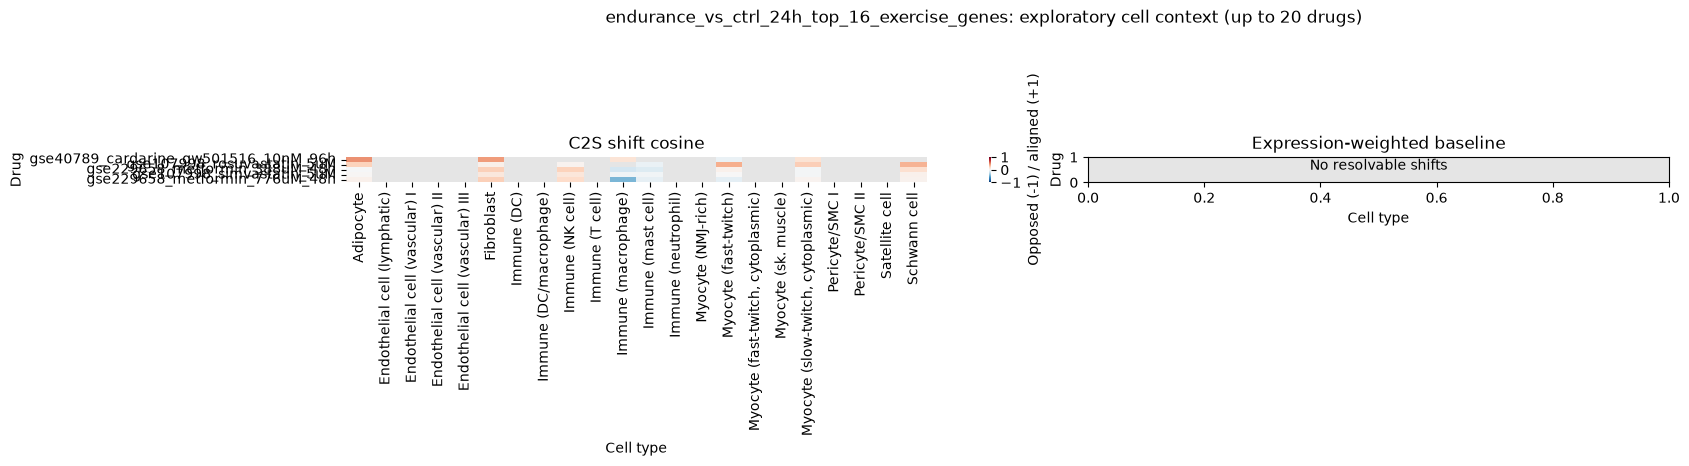

Saved tables, sampled expression, heatmaps, and run settings to /Users/schwepa9/Desktop/Bioascent-hackathon/results/cell_context_c2s


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from importlib.metadata import version


def save_context_results(per_cell, summary, coverage, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    per_cell.to_csv(output_dir / "per_cell_comparisons.csv", index=False)
    summary.to_csv(output_dir / "cell_type_comparisons.csv", index=False)
    coverage.to_csv(output_dir / "signature_coverage.csv", index=False)
    cell_metadata.to_csv(output_dir / "sampled_nuclei.csv", index=False)
    np.savez_compressed(output_dir / "reference_sample.npz", genes=genes, expression=reference_expression)
    shifts = [
        pd.DataFrame({"kind": kind, "signature": name, "gene": signature.index, "applied_log2_shift": signature.to_numpy()})
        for kind, signatures in (("exercise", exercise_signatures), ("drug", drug_signatures))
        for name, signature in signatures.items()
    ]
    pd.concat(shifts, ignore_index=True).to_csv(output_dir / "applied_signature_shifts.csv", index=False)
    manifest = {
        "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
        "model_cache": str(MODEL_CACHE), "device": str(device), "dtype": str(model_dtype),
        "reference_path": str(REFERENCE_PATH), "expression_layer": EXPRESSION_LAYER,
        "gene_symbol_column": GENE_SYMBOL_COLUMN, "cell_type_column": CELL_TYPE_COLUMN,
        "cell_types": CELL_TYPES, "cells_per_type": CELLS_PER_TYPE, "seed": SEED,
        "top_genes": TOP_GENES, "min_genes": MIN_GENES,
        "signature_score_mode": SIGNATURE_SCORE_MODE, "proxy_max_log2fc": SHIFT_LOG2FC,
        "embedding_method": "mean final-layer hidden states over gene tokens, excluding special tokens; raw ranked sentence; no generation",
        "baseline_method": "expression-weighted Pearson correlation of shifts on jointly represented expressed signature genes (at least 3)",
        "aggregation": "mean paired-nucleus similarities within cell type; report valid counts",
        "packages": {name: version(name) for name in ("torch", "transformers", "scanpy", "numpy", "pandas")},
        "interpretation": "Exploratory rank-based comparison; not validated perturbation prediction or causal evidence of exercise blunting.",
    }
    (output_dir / "run_settings.json").write_text(json.dumps(manifest, indent=2) + "\n")


DRUG_LABELS = {
    "gse107998_rosuvastatin_5uM": "Rosuvastatin 5 µM",
    "gse107998_simvastatin_5uM": "Simvastatin 5 µM",
    "gse229658_metformin_388uM_48h": "Metformin 388 µM",
    "gse229658_metformin_776uM_48h": "Metformin 776 µM",
    "gse40789_cardarine_gw501516_10nM_96h": "Cardarine 10 nM",
}
MYOCYTE_TYPES = [
    "Myocyte (NMJ-rich)",
    "Myocyte (fast-twitch)",
    "Myocyte (fast-twitch, cytoplasmic)",
    "Myocyte (sk. muscle)",
    "Myocyte (slow-twitch, cytoplasmic)",
]


def plot_context_summary(summary, per_cell, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for exercise_name, group in summary.groupby("exercise", sort=True):
        ranked = group.groupby("drug")["embedding_cosine"].mean().sort_values(ascending=False)
        drug_order = ranked.index
        labels = [DRUG_LABELS.get(name, name) for name in drug_order]
        matrix = group.pivot(index="drug", columns="cell_type", values="embedding_cosine").reindex(drug_order)
        valid_counts = group.pivot(index="drug", columns="cell_type", values="n_embedding_valid").reindex(drug_order)
        figure, axes = plt.subplots(
            2, 1, figsize=(18, max(8, 0.34 * len(drug_order) + 6)),
            gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True,
        )
        sns.heatmap(
            matrix, ax=axes[0], cmap="RdBu_r", vmin=-0.5, vmax=0.5, center=0,
            mask=matrix.isna(), linewidths=0.35, linecolor="white",
            cbar_kws={"label": "C2S shift cosine (−0.5 to +0.5)"},
        )
        axes[0].set_yticklabels(labels, rotation=0, fontsize=9)
        axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right", fontsize=8)
        axes[0].set_title("C2S embedding-shift similarity by cell type")
        axes[0].set_xlabel("")
        axes[0].set_ylabel("Drug signature")
        sns.heatmap(
            valid_counts, ax=axes[1], cmap="Blues", vmin=0,
            vmax=max(1, int(group["n_cells"].max())), annot=True, fmt=".0f",
            linewidths=0.35, linecolor="white", cbar_kws={"label": "Resolved nuclei"},
        )
        axes[1].set_yticklabels(labels, rotation=0, fontsize=9)
        axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right", fontsize=8)
        axes[1].set_title("Valid C2S scores (out of sampled nuclei per cell type)")
        axes[1].set_xlabel("Cell type")
        axes[1].set_ylabel("Drug signature")
        baseline_note = "expression-weighted baseline unavailable (<3 shared expressed genes)" if group["expression_weighted_correlation"].isna().all() else "blank cells are unresolved"
        figure.suptitle(f"{exercise_name}: exploratory results; {baseline_note}")
        figure.savefig(output_dir / f"{exercise_name}_cell_context.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(figure)

        myocyte_data = per_cell.loc[
            per_cell["exercise"].eq(exercise_name)
            & per_cell["cell_type"].isin(MYOCYTE_TYPES)
            & per_cell["embedding_cosine"].notna()
        ].copy()
        if not myocyte_data.empty:
            myocyte_data["drug_label"] = myocyte_data["drug"].map(DRUG_LABELS).fillna(myocyte_data["drug"])
            figure, axis = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
            sns.stripplot(
                data=myocyte_data, x="embedding_cosine", y="cell_type", hue="drug_label",
                order=MYOCYTE_TYPES, hue_order=[DRUG_LABELS.get(name, name) for name in drug_order],
                dodge=True, jitter=0.12, size=7, alpha=0.85, ax=axis,
            )
            axis.axvline(0, color="#444444", linewidth=1, linestyle="--")
            axis.set_xlim(-1, 1)
            axis.set_xlabel("C2S embedding-shift cosine (individual sampled nuclei)")
            axis.set_ylabel("")
            axis.set_title("Myocyte results; each point is one sampled nucleus")
            axis.legend(title="Drug", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
            figure.savefig(output_dir / f"{exercise_name}_myocyte_points.png", dpi=200, bbox_inches="tight")
            plt.show()
            plt.close(figure)


def plot_signature_overlap(exercises, drugs, output_dir):
    output_dir = Path(output_dir)
    for exercise_name, exercise in exercises.items():
        labels, counts, gene_labels = [], [], []
        for drug_name, drug in drugs.items():
            shared = sorted(set(exercise.index) & set(drug.index))
            labels.append(DRUG_LABELS.get(drug_name, drug_name))
            counts.append(len(shared))
            gene_labels.append(", ".join(shared) if shared else "none")
        figure, axis = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
        positions = np.arange(len(labels))
        axis.barh(positions, counts, color="#4776A8")
        axis.set_yticks(positions, labels)
        axis.invert_yaxis()
        axis.set_xlim(0, max(counts, default=0) + 4)
        for position, count, genes_label in zip(positions, counts, gene_labels):
            axis.text(count + 0.1, position, f"{count}: {genes_label}", va="center", fontsize=9)
        axis.set_xlabel("Genes shared with exercise signature")
        axis.set_title(f"Gene-level overlap: {exercise_name}")
        figure.savefig(output_dir / f"{exercise_name}_signature_overlap.png", dpi=200, bbox_inches="tight")
        plt.show()
        plt.close(figure)


if reference_expression is not None:
    per_cell_results, cell_type_results, signature_coverage = compare_cell_context(
        reference_expression, genes, cell_metadata, exercise_signatures, drug_signatures
    )
    save_context_results(per_cell_results, cell_type_results, signature_coverage, OUTPUT_DIR)
    print(cell_type_results.to_string(index=False))
    plot_context_summary(cell_type_results, per_cell_results, OUTPUT_DIR)
    plot_signature_overlap(exercise_signatures, drug_signatures, OUTPUT_DIR)
    print(f"Saved tables, sampled expression, heatmaps, myocyte point plots, and run settings to {OUTPUT_DIR}")
else:
    print("Set the data paths in Cell 2, supply inputs, then rerun Cells 6-8. No synthetic biological results are generated.")

In [ ]:
# Re-render presentation figures from saved results without rerunning model inference.
summary_path = OUTPUT_DIR / "cell_type_comparisons.csv"
per_cell_path = OUTPUT_DIR / "per_cell_comparisons.csv"
shifts_path = OUTPUT_DIR / "applied_signature_shifts.csv"
if not all(path.is_file() for path in (summary_path, per_cell_path, shifts_path)):
    raise FileNotFoundError("Run the comparison cell first; saved comparison tables are missing.")

saved_summary = pd.read_csv(summary_path)
saved_per_cell = pd.read_csv(per_cell_path)
saved_shifts = pd.read_csv(shifts_path)
saved_signatures = {
    (kind, name): group.set_index("gene")["applied_log2_shift"]
    for (kind, name), group in saved_shifts.groupby(["kind", "signature"])
}
saved_exercises = {
    name: saved_signatures["exercise", name]
    for kind, name in saved_signatures if kind == "exercise"
}
saved_drugs = {
    name: saved_signatures["drug", name]
    for kind, name in saved_signatures if kind == "drug"
}
plot_context_summary(saved_summary, saved_per_cell, OUTPUT_DIR)
plot_signature_overlap(saved_exercises, saved_drugs, OUTPUT_DIR)
print(f"Presentation figures saved under {OUTPUT_DIR}")